# 05 — Stellar tides

In 04, mass loss widened the orbit while the brown dwarf changed its eccentricity. Here we let the star and planet raise tides on each other. Does the planet still clear the giant’s surface? Run All reads the results. Enable the variables below to run SecularMultiple on your PC and test it out.


In [ ]:
from pathlib import Path

RUN_PC_BENCHMARK = False  # Original evolving AGB triple; about 2 h 17 min on Kostas’ laptop, if someone else runs it on theirs, do let me know how long it takes
RUN_SHORT_TIDES = False
RUN_GIANT_TRIPLE = False
GIANT_INTERVALS = 250_000      # Per triple, over 5 Myr
GIANT_STAR_VISCOUS_YR = 1.0
PLOT_SAVED_AGB = False

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" and not (cwd / "data").is_dir() else cwd
AGB_REFERENCE_PATH = Path("data/tidal_runs/refined_AGB_20261110T185757Z_1432e7/combined_pre_WD_v1")
REFERENCE = PROJECT_ROOT / AGB_REFERENCE_PATH


In [ ]:
import json
import os
import warnings
from contextlib import contextmanager
from time import perf_counter
import numpy as np
from datetime import datetime as _bench_datetime, timezone as _bench_timezone
import hashlib as _bench_hashlib
from importlib import metadata as _bench_metadata
from importlib.util import find_spec as _bench_find_spec
import json as _bench_json
from numbers import Integral as _bench_Integral
import os as _bench_os
from pathlib import Path as _bench_Path
import platform as _bench_platform
import re as _bench_re
import subprocess as _bench_subprocess
import tempfile as _bench_tempfile
from time import perf_counter as _bench_perf_counter


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


# Fixed-structure binary and triple exercises
def fixed_tree(n_bodies):
    """Allocate physical bodies followed by their binary orbit records."""
    import numpy as np
    from amuse.datamodel import Particles
    from amuse.units import units

    tree = Particles(2 * n_bodies - 1)
    tree.is_binary = [False] * n_bodies + [True] * (n_bodies - 1)
    tree.child1 = tree.child2 = None
    tree.mass = 0.0 | units.MSun
    tree.radius = 1e-15 | units.au
    tree.semimajor_axis = 0.08 | units.au
    tree.eccentricity = 0.2
    tree.inclination = np.deg2rad(5.0)
    tree.argument_of_pericenter = tree.longitude_of_ascending_node = 0.0
    for name in ("include_pairwise_1PN_terms", "include_pairwise_25PN_terms",
                 "include_tidal_friction_terms", "include_tidal_bulges_precession_terms",
                 "include_rotation_precession_terms"):
        setattr(tree, name, False)
    for axis in "xyz":
        setattr(tree, "spin_vec_" + axis, 0.0 | (1 / units.yr))
    inner = tree[n_bodies]
    inner.child1, inner.child2 = tree[0], tree[1]
    return tree


def set_inner_tides(tree, inner, star_friction, planet_friction, star_tv, planet_tv,
                    star_spin_fraction, precession=False):
    """Align the initial spins with the inner orbit. Both node longitudes are zero."""
    import numpy as np
    from amuse.units import units

    star, planet = tree[0], tree[1]
    total_mass = (star.mass + planet.mass).value_in(units.MSun)
    a0 = inner.semimajor_axis.value_in(units.au)
    n0 = np.sqrt(39.4852492465 * total_mass / a0**3)
    for body, friction, tv, apsidal, kappa, spin in (
        (star, star_friction, star_tv, 0.014, 0.08, star_spin_fraction * n0),
        (planet, planet_friction, planet_tv, 0.30, 0.25, n0),
    ):
        body.tides_method = 2
        body.tides_viscous_time_scale_prescription = 0
        body.tides_viscous_time_scale = tv | units.yr
        body.tides_apsidal_motion_constant = apsidal
        body.tides_gyration_radius = kappa
        body.include_tidal_friction_terms = friction
        body.include_tidal_bulges_precession_terms = precession
        body.include_rotation_precession_terms = precession
        body.spin_vec_y = float(-spin * np.sin(inner.inclination)) | (1 / units.yr)
        body.spin_vec_z = float(spin * np.cos(inner.inclination)) | (1 / units.yr)


def fixed_history(tree, inner_index, duration_yr, n_intervals):
    """Sample the inner orbit at equally spaced times, including both endpoints."""
    import numpy as np
    from amuse.community.secularmultiple.interface import SecularMultiple
    from amuse.units import units

    worker = SecularMultiple(channel_type="sockets")
    try:
        worker.parameters.relative_tolerance = 1e-11
        worker.parameters.absolute_tolerance_eccentricity_vectors = 1e-13
        worker.parameters.include_quadrupole_order_terms = True
        worker.parameters.include_octupole_order_binary_pair_terms = True
        particles = worker.particles.add_particles(tree)
        tree.new_channel_to(worker.particles).copy()
        worker.commit_particles()
        binary = particles[inner_index]
        ages = np.linspace(0, duration_yr, n_intervals + 1)
        a = [binary.semimajor_axis.value_in(units.au)]
        e = [binary.eccentricity]
        contact = False
        for index, dt in enumerate(np.diff(ages), start=1):
            elapsed, _, flag, error = worker.evolve_interface(0.0 | units.yr, float(dt) | units.yr)
            step = elapsed.value_in(units.yr)
            contact = flag == 2 and binary.physical_collision_or_orbit_crossing_has_occurred
            if error != 0 or not np.isfinite(step) or not (0 <= step <= dt + 1e-8):
                raise RuntimeError(f"Unexpected worker return: flag={flag}, error={error}, dt={elapsed}")
            if not contact and (flag != 0 or not np.isclose(step, dt, rtol=1e-12, atol=1e-8)):
                raise RuntimeError(f"Unexpected worker return: flag={flag}, error={error}, dt={elapsed}")
            a.append(binary.semimajor_axis.value_in(units.au))
            e.append(binary.eccentricity)
            if contact:
                ages[index] = ages[index - 1] + step
                break
        return ages[:len(a)], np.asarray(a), np.asarray(e), contact
    finally:
        worker.stop()


def tidal_control(tides_on, stellar_viscous_yr):
    """Evolve the aligned, fixed-structure binary with AMUSE SecularMultiple."""
    from amuse.units import units

    if stellar_viscous_yr <= 0:
        raise ValueError("Choose a positive stellar viscous time.")
    tree = fixed_tree(2)
    tree[:2].mass = [1.0, 0.001] | units.MSun
    tree[:2].radius = [0.02, 0.0005] | units.au
    set_inner_tides(tree, tree[2], tides_on, tides_on, stellar_viscous_yr, 0.01, 0.2)
    t, a, e, _ = fixed_history(tree, 2, duration_yr=10_000, n_intervals=32)
    return t, a, e


def frozen_giant(star_friction, n_intervals, stellar_viscous_yr=1.0):
    """Compare stellar dissipation in the same inclined triple at fixed stellar structure."""
    import numpy as np
    from amuse.units import units

    if not np.isfinite(stellar_viscous_yr) or stellar_viscous_yr <= 0:
        raise ValueError("Choose a finite, positive stellar viscous time.")
    tree = fixed_tree(3)
    star, planet, bd, inner, outer = tree
    star.mass, star.radius = 1.2 | units.MSun, 0.75 | units.au
    planet.mass, planet.radius = 1.9 | units.MEarth, 1.2 | units.REarth
    bd.mass, bd.radius = 27 | units.MJupiter, 1 | units.RJupiter
    outer.child1, outer.child2 = inner, bd
    inner.semimajor_axis, outer.semimajor_axis = 5 | units.au, 100 | units.au
    inner.eccentricity = outer.eccentricity = 0.001
    inner.inclination, outer.inclination = np.deg2rad([65.0, 5.0])
    inner.include_pairwise_1PN_terms = True
    inner.check_for_physical_collision_or_orbit_crossing = True
    set_inner_tides(tree, inner, star_friction, True, stellar_viscous_yr, 1.0, 0.1, precession=True)

    t, a, e, contact = fixed_history(tree, 3, duration_yr=5_000_000, n_intervals=n_intervals)
    q = a * (1 - e)
    clearance = q - (star.radius + planet.radius).value_in(units.au)
    return t, a, q, clearance, contact




_BENCH_SCHEMA = "amuse_pc_benchmark_v1"


def _bench_read(path):
    try:
        return _bench_Path(path).read_text(errors="replace").strip()
    except OSError:
        return ""


def _bench_sysctl(key):
    try:
        return _bench_subprocess.check_output(["sysctl", "-n", key], text=True, timeout=2,
                                       stderr=_bench_subprocess.DEVNULL).strip()
    except (OSError, _bench_subprocess.SubprocessError):
        return ""


def _bench_version(*names, source_package=None):
    for name in names:
        try:
            return _bench_metadata.version(name)
        except _bench_metadata.PackageNotFoundError:
            pass
    if source_package:
        spec = _bench_find_spec(source_package)
        if spec is not None and spec.origin:
            text = _bench_read(_bench_Path(spec.origin).with_name("_version.py"))
            match = _bench_re.search(r"""^__version__\s*=\s*["']([^"']+)["']""", text, _bench_re.M)
            if match:
                return match.group(1)
    return None


def _bench_windows_ram():
    import ctypes
    # MEMORYSTATUSEX contains two DWORDs followed by eight-byte counters.
    class Memory(ctypes.Structure):
        _fields_ = [("length", ctypes.c_uint32), ("load", ctypes.c_uint32),
                    ("physical", ctypes.c_uint64), ("other", ctypes.c_uint64 * 6)]
    info = Memory()
    info.length = ctypes.sizeof(info)
    if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(info)):
        return info.physical
    return None


def machine_specs():
    """Return portable hardware and software fields without user or machine identifiers."""
    system = _bench_platform.system()
    cpu = _bench_platform.processor() or _bench_platform.machine()
    cores, ram, affinity = None, None, None
    os_name = system
    if system == "Linux":
        cpuinfo = _bench_read("/proc/cpuinfo")
        for key in ("model name", "Hardware", "Processor"):
            model = _bench_re.search(rf"^{key}\s*:\s*(\S[^\n]*)", cpuinfo, _bench_re.M)
            if model:
                cpu = model.group(1).strip()
                break
        core_pairs = set()
        for block in cpuinfo.split("\n\n"):
            fields = dict(line.split(":", 1) for line in block.splitlines() if ":" in line)
            fields = {k.strip(): v.strip() for k, v in fields.items()}
            if "physical id" in fields and "core id" in fields:
                core_pairs.add((fields["physical id"], fields["core id"]))
        cores = len(core_pairs) or None
        mem = _bench_re.search(r"^MemTotal:\s*(\d+) kB", _bench_read("/proc/meminfo"), _bench_re.M)
        ram = int(mem.group(1)) * 1024 if mem else None
        try:
            os_name = _bench_platform.freedesktop_os_release().get("PRETTY_NAME", system)
        except (OSError, AttributeError):
            pass
    elif system == "Darwin":
        cpu = _bench_sysctl("machdep.cpu.brand_string") or cpu
        cores = int(_bench_sysctl("hw.physicalcpu") or 0) or None
        ram = int(_bench_sysctl("hw.memsize") or 0) or None
        os_name = "macOS " + _bench_platform.mac_ver()[0]
    elif system == "Windows":
        cpu = _bench_os.environ.get("PROCESSOR_IDENTIFIER") or cpu
        ram = _bench_windows_ram()
    if hasattr(_bench_os, "sched_getaffinity"):
        try:
            affinity = sorted(_bench_os.sched_getaffinity(0))
        except OSError:
            pass
    thread_env = {k: _bench_os.environ[k] for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
                  "MKL_NUM_THREADS", "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
                  if _bench_re.fullmatch(r"[0-9 ,]+", _bench_os.environ.get(k, ""))}
    return {
        "os": os_name, "os_release": _bench_platform.release(), "machine_arch": _bench_platform.machine(),
        "cpu_model": cpu, "physical_cores": cores, "logical_cpus": _bench_os.cpu_count(),
        "affinity_cpus": affinity, "ram_bytes": ram, "thread_settings": thread_env,
        "software": {"python": _bench_platform.python_version(), "numpy": _bench_version("numpy"),
                     "amuse": _bench_version("amuse-framework", "amuse", source_package="amuse"),
                     "amuse_secularmultiple": _bench_version("amuse-secularmultiple", source_package="amuse_secularmultiple")},
    }


def _bench_now():
    return _bench_datetime.now(_bench_timezone.utc).isoformat(timespec="seconds")


def _bench_write(path, report):
    pending = path.with_suffix(".tmp")
    pending.write_text(_bench_json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    pending.replace(path)


def run_benchmark(output_root, workload_id, input_files, settings, run_case):
    if not _bench_re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*", workload_id):
        raise ValueError("Use a short workload ID with letters, digits, dots, dashes, or underscores.")
    payload = {}
    for label, path in sorted(input_files.items()):
        with _bench_Path(path).open("rb") as handle:
            digest = _bench_hashlib.sha256()
            for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(chunk)
            payload[label] = {"sha256": digest.hexdigest(), "bytes": _bench_os.fstat(handle.fileno()).st_size}
    ident = {"workload_id": workload_id, "inputs": payload, "settings": settings}
    canonical = _bench_json.dumps(ident, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()
    root = _bench_Path(output_root).resolve()
    root.mkdir(parents=True, exist_ok=True)
    trial = _bench_Path(_bench_tempfile.mkdtemp(prefix=workload_id + "-", dir=root))
    path = trial / "benchmark.json"
    machine = machine_specs()
    report = {"schema": _BENCH_SCHEMA, **ident, "workload_sha256": _bench_hashlib.sha256(canonical).hexdigest(),
              "machine": machine, "started_utc": _bench_now(), "status": "running"}
    _bench_write(path, report)
    print(f"Fresh benchmark results: {path}", flush=True)
    start = _bench_perf_counter()
    try:
        result = dict(run_case(trial / "case"))
        seconds = _bench_perf_counter() - start
        if (isinstance(result["n_states"], bool) or not isinstance(result["n_states"], _bench_Integral)
                or result["n_states"] < 1 or not isinstance(result["outcome"], str) or not result["outcome"]):
            raise ValueError("The case must report a positive integer n_states and a terminal outcome.")
        result["n_states"] = int(result["n_states"])
        _bench_json.dumps(result, allow_nan=False)
    except BaseException as exc:
        report.update(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
                      finished_utc=_bench_now(), wall_seconds=_bench_perf_counter() - start, error_type=type(exc).__name__)
        _bench_write(path, report)
        raise
    report.update(status="completed", finished_utc=_bench_now(), wall_seconds=seconds, result=result)
    _bench_write(path, report)
    return path


def _bench_hardware_columns(hw):
    affinity = hw["affinity_cpus"]
    counts = [hw["physical_cores"], hw["logical_cpus"], len(affinity) if affinity is not None else None]
    cpu = hw["cpu_model"] + " (" + "/".join(str(c) if c is not None else "?" for c in counts) + ")"
    ram = f"{hw['ram_bytes']/2**30:.1f}" if hw["ram_bytes"] is not None else "?"
    return cpu, ram


def compare_reports(paths):
    """Use independent baselines for each workload, fingerprint, terminal outcome and state count."""
    if isinstance(paths, (str, _bench_os.PathLike)):
        paths = [paths]
    groups = {}
    historical = []
    for i, path in enumerate(paths, 1):
        report = _bench_json.loads(_bench_Path(path).read_text(encoding="utf-8"))
        if report.get("schema") == "reference_pc_v1":
            historical.append((i, report))
            continue
        if report.get("schema") != _BENCH_SCHEMA:
            raise ValueError(f"Unrecognized benchmark report: {path}")
        key = (report["workload_id"], report["workload_sha256"])
        groups.setdefault(key, []).append((i, report))
    for (workload, fingerprint), entries in groups.items():
        print(f"\n{workload}  SHA-256 {fingerprint}")
        print("PC  | CPU (physical cores / logical CPUs / affinity count) | RAM GiB | "
              "wall min | s/1000 states | relative speed | outcome | states")
        baselines = {}
        for index, report in entries:
            cpu, ram = _bench_hardware_columns(report["machine"])
            seconds = report.get("wall_seconds")
            elapsed = f"{seconds / 60:.2f}" if seconds is not None else "—"
            scaled = speed = "—"
            result = report.get("result", {})
            outcome = result.get("outcome", report["status"])
            count = result.get("n_states")
            if report["status"] == "completed" and count and seconds is not None and seconds > 0:
                scaled = f"{seconds * 1000 / count:.3f}"
                if report.get("settings", {}).get("embedded_code", {}).get("source_kind", "executed") != "executed":
                    speed = "code unverified"
                elif result.get("reference_match", True):
                    key = (outcome, count)
                    if key in baselines:
                        first, baseline = baselines[key]
                        speed = f"{baseline / seconds:.2f}x vs PC{first}"
                    else:
                        baselines[key] = (index, seconds)
                        speed = "baseline"
                else:
                    speed = "reference mismatch"
            print(f"PC{index} | {cpu} | {ram} | {elapsed} | {scaled} | {speed} | {outcome} | {count or '—'}")

    for index, old in historical:
        cpu, ram = _bench_hardware_columns(old["machine"])
        print(f"\nPC{index} historical case timers. Specs captured {old['captured_utc']}: "
              f"{cpu}, {ram} GiB RAM.")
        for label, row in sorted(old["reference_runs"].items()):
            print(f"{label} | {row['case']} | {row['wall_seconds']/60:.2f} min | {row['concurrency']}")

def _bench_symbol_signature(obj):
    """Keep identity guards in memory only. Source fingerprints are independent of interpreter bytecode."""
    if isinstance(obj, type):
        members = []
        for name, method in vars(obj).items():
            method = getattr(method, "__func__", method)
            if hasattr(method, "__code__"):
                members.append((name, _bench_symbol_signature(method)))
        return (obj, tuple(members))
    func = obj
    while hasattr(func, "__wrapped__"):
        func = func.__wrapped__
    return (obj, getattr(obj, "__code__", None), getattr(func, "__code__", None))


def bench_register_setup(distributed_sha256, source=None):
    """Capture the executed solver block, or identify the distributed version when cell text is unavailable."""
    if not _bench_re.fullmatch(r"[a-f0-9]{64}", distributed_sha256):
        raise ValueError("The distributed workload fingerprint must be a SHA-256 digest.")
    if source is None:
        shell = globals().get("get_ipython")
        if shell is None:
            import builtins
            shell = getattr(builtins, "get_ipython", None)
        shell = shell() if callable(shell) else None
        for owner in (getattr(shell, "kernel", None), shell):
            get_parent = getattr(owner, "get_parent", None)
            if callable(get_parent):
                try:
                    message = get_parent()
                except (AttributeError, KeyError, RuntimeError, TypeError):
                    continue
                if isinstance(message, dict):
                    source = message.get("content", {}).get("code")
                    if isinstance(source, str) and source:
                        break

    begin = "# BEGIN BENCHMARK WORKLOAD"
    end = "# END BENCHMARK WORKLOAD"
    lines = source.replace("\r\n", "\n").split("\n") if isinstance(source, str) else []
    digest, kind = distributed_sha256, "distributed_fallback"
    if lines.count(begin) == lines.count(end) == 1 and lines.index(begin) < lines.index(end):
        block = "\n".join(lines[lines.index(begin) + 1:lines.index(end)]).strip("\n")
        digest = _bench_hashlib.sha256(block.encode("utf-8")).hexdigest()
        kind = "executed"
    global _BENCH_SETUP_SIGNATURES, _BENCH_SETUP_CODE
    _BENCH_SETUP_SIGNATURES = {
        key: _bench_symbol_signature(obj) for key, obj in list(globals().items())
        if isinstance(obj, type) or hasattr(obj, "__code__")
    }
    _BENCH_SETUP_CODE = {"sha256": digest, "source_kind": kind}


def bench_source_fingerprint(symbols, constants=None):
    """Identify the scientific definitions used in this case and the effective constant values."""
    code = _BENCH_SETUP_CODE.copy()
    # Objects may have been redefined interactively after this setup cell ran.
    # Record that uncertainty rather than compare machines using a stale source ID.
    used = {}
    for obj in symbols:
        name = obj.__name__
        used[name] = _BENCH_SETUP_SIGNATURES.get(name) == _bench_symbol_signature(obj)
    if not all(used.values()):
        code["source_kind"] = "changed_after_setup"
    code["symbols"] = sorted(used)
    code["constants"] = constants if constants is not None else {}
    return code


# Orbital state, changing stellar structure and wind torque for the AGB case
G = 39.4852492465  # AU³ / (solar mass yr²)


@contextmanager
def coupled_working_directory(path):
    previous = Path.cwd()
    os.chdir(path)
    try:
        yield
    finally:
        os.chdir(previous)


class TidalAmuseBackend:
    """Keep AMUSE calls separate from the interval and comparison logic."""
    def __init__(self, cfg, mass, radius, quadrupole, rtol, atol, events, worker_options):
        from amuse.units import units
        from amuse.datamodel import Particles
        from amuse.community.secularmultiple.interface import SecularMultiple
        self.units = units
        self.cfg = cfg
        self.solver = SecularMultiple(**worker_options)
        self.H = 0.0
        try:
            p = self.solver.parameters
            p.relative_tolerance = rtol
            p.absolute_tolerance_eccentricity_vectors = atol
            p.include_quadrupole_order_terms = quadrupole
            for name in ("include_octupole_order_binary_pair_terms", "include_octupole_order_binary_triplet_terms",
                         "include_hexadecupole_order_binary_pair_terms", "include_dotriacontupole_order_binary_pair_terms"):
                setattr(p, name, False)
            tree = Particles(5)
            tree.is_binary = [False, False, False, True, True]
            tree.child1 = None
            tree.child2 = None
            tree.mass = [mass, cfg["m_planet_MSun"], cfg["m_bd_MSun"], 0, 0] | units.MSun
            tree.radius = [radius, cfg["r_planet_AU"], cfg["r_bd_AU"], 1e-15, 1e-15] | units.au
            for axis in "xyz":
                setattr(tree, "spin_vec_"+axis, 0.0 | (1/units.yr))
            tree.semimajor_axis = 1.0 | units.au
            tree.eccentricity = 1e-3
            tree.inclination = 0.1
            tree.argument_of_pericenter = 0.0
            tree.longitude_of_ascending_node = 0.0
            tree[3].child1, tree[3].child2 = tree[0], tree[1]
            tree[4].child1, tree[4].child2 = tree[3], tree[2]
            for suffix, i, inc in (("in", 3, cfg["outer_inclination_deg"]+cfg["mutual_inclination_deg"]),
                                   ("out", 4, cfg["outer_inclination_deg"])):
                tree[i].semimajor_axis = cfg["a_"+suffix+"_AU"] | units.au
                tree[i].eccentricity = cfg["e_"+suffix]
                tree[i].inclination = float(np.deg2rad(inc))
            for name in ("include_pairwise_1PN_terms", "include_pairwise_25PN_terms", "include_tidal_friction_terms",
                         "include_tidal_bulges_precession_terms", "include_rotation_precession_terms",
                         "check_for_secular_breakdown", "check_for_dynamical_instability",
                         "check_for_physical_collision_or_orbit_crossing", "check_for_minimum_periapse_distance",
                         "check_for_RLOF_at_pericentre", "sample_orbital_phases_randomly"):
                setattr(tree, name, False)
            tree.mass_dot_external = 0.0 | (units.MSun/units.yr)
            tree.radius_dot_external = 0.0 | (units.au/units.yr)
            tree.radius_ddot_external = 0.0 | (units.au/units.yr**2)
            if events:
                tree[3].check_for_physical_collision_or_orbit_crossing = True
                tree[4].check_for_physical_collision_or_orbit_crossing = True
                tree[3].check_for_secular_breakdown = quadrupole
                tree[3].check_for_dynamical_instability = True
                tree[3].dynamical_instability_criterion = 0
            normal = np.array([0., -np.sin(tree[3].inclination), np.cos(tree[3].inclination)])
            frequency = np.sqrt(G*(mass+cfg["m_planet_MSun"])/cfg["a_in_AU"]**3)
            for i, name in ((0, "star"), (1, "planet")):
                tree[i].tides_method = 2
                tree[i].tides_viscous_time_scale_prescription = 0
                tree[i].tides_viscous_time_scale = cfg[f"tV_{name}_yr"] | units.yr
                tree[i].tides_apsidal_motion_constant = cfg[f"k_{name}"]
                tree[i].tides_gyration_radius = cfg[f"kappa_{name}"]
                tree[i].include_tidal_friction_terms = cfg["tides"]
                tree[i].include_tidal_bulges_precession_terms = cfg["tidal_bulges"]
                tree[i].include_rotation_precession_terms = cfg["rotation_bulges"]
                for axis, value in zip("xyz", normal*frequency*cfg[f"spin_{name}_over_n"]):
                    setattr(tree[i], "spin_vec_"+axis, float(value) | (1/units.yr))
            self.remote = self.solver.particles.add_particles(tree)
            tree.new_channel_to(self.solver.particles).copy()
            self.solver.commit_particles()
            self.H = float(self.solver.initial_hamiltonian.value_in(units.MSun*units.au**2/units.yr**2))
        except BaseException:
            self.stop()
            raise

    def set_rates(self, mdot, rdot):
        self.remote[0].mass_dot_external = float(mdot) | (self.units.MSun/self.units.yr)
        self.remote[0].radius_dot_external = float(rdot) | (self.units.au/self.units.yr)

    def advance(self, dt):
        u = self.units
        elapsed, H, flag, error = self.solver.evolve_interface(0.0 | u.yr, float(dt) | u.yr)
        elapsed = float(elapsed.value_in(u.yr))
        self.H = float(H.value_in(u.MSun*u.au**2/u.yr**2))
        flag, error = int(flag), int(error)
        if error != 0 or flag not in (0, 2):
            raise RuntimeError(f"SecularMultiple flag={flag}, error={error}")
        events = []
        if flag == 2:
            for i, name in ((3, "surface_contact"), (4, "orbit_crossing")):
                if self.remote[i].physical_collision_or_orbit_crossing_has_occurred:
                    events.append(name)
            for attribute, name in (("secular_breakdown_has_occurred", "secular_breakdown"),
                                    ("dynamical_instability_has_occurred", "instability_criterion")):
                if getattr(self.remote[3], attribute):
                    events.append(name)
            if not events:
                raise RuntimeError("Root return without an identified event.")
        return elapsed, "+".join(events)

    def snapshot(self):
        u, p = self.units, self.remote
        row = {"mass_MSun": float(p[0].mass.value_in(u.MSun)),
               "radius_AU": float(p[0].radius.value_in(u.au)), "hamiltonian": self.H}
        normals = []
        for suffix, i in (("in", 3), ("out", 4)):
            row["a_"+suffix+"_AU"] = float(p[i].semimajor_axis.value_in(u.au))
            row["e_"+suffix] = float(p[i].eccentricity)
            h = np.asarray(p[i].h_vec.value_in(u.MSun*u.au**2/u.yr), dtype=float)
            for axis, value in zip("xyz", h):
                row[f"h_{suffix}_{axis}"] = float(value)
            normals.append(h/np.linalg.norm(h))
        row["mutual_inclination_deg"] = float(np.rad2deg(np.arccos(np.clip(np.dot(*normals), -1, 1))))
        for i, name in ((0, "star"), (1, "planet")):
            for axis in "xyz":
                row[f"omega_{name}_{axis}"] = float(
                    getattr(p[i], "spin_vec_"+axis).value_in(1/u.yr)
                )
        return row

    def stop(self):
        try:
            self.solver.stop()
        except Exception as exc:
            warnings.warn(f"Worker cleanup: {exc!r}")


class WDCheckpointBackend(TidalAmuseBackend):
    def checkpoint(self):
        state = self.snapshot()
        for suffix, i in (('in', 3), ('out', 4)):
            for axis in 'xyz':
                state[f'ev_{suffix}_{axis}'] = float(getattr(self.remote[i], 'e_vec_'+axis))
        return state



class TidalCheckBackend(WDCheckpointBackend):
    def __init__(self, *args, extra_physics=None, **kwargs):
        self.extra_physics = dict(extra_physics or {})
        super().__init__(*args, **kwargs)
        try:
            self.solver.parameters.include_octupole_order_binary_pair_terms = bool(
                self.extra_physics.get('octupole', False))
            self.remote[3].include_pairwise_1PN_terms = bool(
                self.extra_physics.get('GR', False))
            self.set_rates(0., 0.)
            self.advance(0.)
        except BaseException:
            self.stop()
            raise

    def set_rates(self, mdot, rdot):
        super().set_rates(mdot, rdot)
        if not self.extra_physics.get('wind_spin', False) and getattr(self,'_wind_zeroed',False):
            return
        rate = np.zeros(3)
        if self.extra_physics.get('wind_spin', False):
            if mdot > 0:
                raise ValueError('This wind prescription only covers mass loss.')
            mass = float(self.remote[0].mass.value_in(self.units.MSun))
            omega = np.array([float(getattr(self.remote[0], 'spin_vec_'+a).value_in(
                1/self.units.yr)) for a in 'xyz'])
            # Only add wind torque / I; the worker already changes I with M and R.
            rate = (2/(3*self.cfg['kappa_star']))*(mdot/mass)*omega
        particles = self.solver.particles
        indices = particles.get_indices_of_keys(self.remote[[0]].key)
        names = [f'spin_vec_{a}_dot_external' for a in 'xyz']
        values = [np.array([v]) | (1/self.units.yr**2) for v in rate]
        particles.set_values_in_store(indices, names, values)
        self._wind_zeroed = not self.extra_physics.get('wind_spin',False)


def enrich_state(row, cfg, initial_mass):
    mp = cfg['m_planet_MSun']
    spin_J = np.zeros(3)
    spin_energy = 0.0
    for name, mass, radius in (
        ('star', row['mass_MSun'], row['radius_AU']),
        ('planet', mp, cfg['r_planet_AU']),
    ):
        omega = np.array([row[f'omega_{name}_{axis}'] for axis in 'xyz'])
        inertia = cfg[f'kappa_{name}']*mass*radius**2
        spin_J += inertia*omega
        spin_energy += 0.5*inertia*np.dot(omega, omega)
        row[f'spin_{name}_over_breakup'] = float(np.linalg.norm(omega)/np.sqrt(G*mass/radius**3))
    hin = np.array([row[f'h_in_{axis}'] for axis in 'xyz'])
    hout = np.array([row[f'h_out_{axis}'] for axis in 'xyz'])
    for axis, inner, total in zip('xyz', hin+spin_J, hin+hout+spin_J):
        row[f'J_inner_spin_{axis}'] = float(inner)
        row[f'J_total_{axis}'] = float(total)
    row['E_mechanical'] = -G*row['mass_MSun']*mp/(2*row['a_in_AU'])+spin_energy
    row['q_in_AU'] = row['a_in_AU']*(1-row['e_in'])
    row['clearance_AU'] = row['q_in_AU']-row['radius_AU']-cfg['r_planet_AU']
    for suffix in ('in', 'out'):
        extra = mp+(cfg['m_bd_MSun'] if suffix == 'out' else 0)
        row[f'aM_{suffix}_ratio'] = (
            row[f'a_{suffix}_AU']*(row['mass_MSun']+extra)
            /(cfg[f'a_{suffix}_AU']*(initial_mass+extra))
        )
    return row


def summarize(label, h, outcome):
    return {
        'run': label, 'outcome': outcome, 'n_states': len(h['time_yr']),
        'end_time_yr': float(h['time_yr'][-1]),
        'end_age_Myr': float(h['age_Myr'][-1]),
        'final_a_in_AU': float(h['a_in_AU'][-1]),
        'final_e_in': float(h['e_in'][-1]),
        'sampled_emax': float(h['e_in'].max()),
        'minimum_sampled_clearance_AU': float(h['clearance_AU'].min()),
        'max_rel_mass_driver_error': float(np.max(abs(h['mass_MSun']/h['driver_mass_MSun']-1))),
        'max_rel_radius_driver_error': float(np.max(abs(h['radius_AU']/h['driver_radius_AU']-1))),
        'max_abs_radius_driver_error_AU': float(np.max(abs(h['radius_AU']-h['driver_radius_AU']))),
        'max_aM_in_error': float(np.max(abs(h['aM_in_ratio']-1))),
        'max_aM_out_error': float(np.max(abs(h['aM_out_ratio']-1))),
        'max_spin_star_over_breakup': float(h['spin_star_over_breakup'].max()),
        'max_spin_planet_over_breakup': float(h['spin_planet_over_breakup'].max()),
    }


# Evolve the archived AGB case and check its endpoint
AGB_WORKLOAD = "05_combined_AGB2048_n1"
AGB_PHYSICS = {"GR": True, "octupole": True, "wind_spin": True}


def coupled_save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")


def wd_write(path, value):
    # Atomic records allow an interrupted replay to resume from a full checkpoint.
    path = Path(path)
    temp = path.with_name(path.name+'.tmp')
    temp.write_text(json.dumps(value, indent=2, allow_nan=False)+'\n')
    temp.replace(path)


def _run_fresh_case(folder, window, cfg, targets, rtol, atol, worker_options):
    """Original 05 loop and disk IO. The benchmark harness supplies a fresh case path."""
    times, masses, radii = [np.asarray(window[k], dtype=float) for k in
                           ('time_yr', 'mass_MSun', 'radius_AU')]
    if (times.ndim != 1 or len(times) < 2 or times[0] != 0
        or masses.shape != times.shape or radii.shape != times.shape
        or not all(np.isfinite(x).all() for x in (times, masses, radii, targets))
        or np.any(np.diff(times) <= 0) or np.any(np.diff(targets) <= 0)
        or np.any(masses <= 0) or np.any(radii <= 0)
        or targets[0] != 0 or targets[-1] != times[-1]
        or not np.isin(times, targets).all()):
        raise ValueError('Require valid drivers and a common grid containing every source knot.')
    positive = ('m_planet_MSun','m_bd_MSun','r_planet_AU','r_bd_AU','a_in_AU','a_out_AU',
                'tV_star_yr','tV_planet_yr','kappa_star','kappa_planet')
    if (not all(np.isfinite(v) for v in cfg.values()) or any(cfg[k] <= 0 for k in positive)
        or not all(0 < cfg[k] < 1 for k in ('e_in','e_out'))
        or min(cfg['k_star'], cfg['k_planet']) < 0):
        raise ValueError('Invalid tidal/orbital settings.')
    if cfg['a_in_AU']*(1-cfg['e_in']) <= radii[0]+cfg['r_planet_AU']:
        raise ValueError('The initial orbit already intersects the stellar surface.')
    inputs = {
        'cfg':cfg, 'quadrupole':True, 'rtol':rtol, 'atol':atol, 'events':True,
        'source':window['source'], 'age_offset_Myr':window['age_offset_Myr'],
        'worker_options':worker_options, 'planned_outputs':len(targets),
        'storage':'structured_numpy_history_v1',
    }
    driver_keys = ('time_yr','mass_MSun','radius_AU','stellar_type')
    folder.mkdir()
    np.savez_compressed(folder / 'driver.npz', **{k:window[k] for k in driver_keys})
    np.save(folder / 'targets.npy', targets)
    info = {'status':'started', 'inputs':inputs, 'n_states':0}
    coupled_save_json(folder / 'run.json', info)
    mdot, rdot = np.diff(masses)/np.diff(times), np.diff(radii)/np.diff(times)
    table, backend, size = None, None, 0
    outcome, previous = 'completed_window', 0.0
    started = last_print = perf_counter()
    overlap_index = max(0,int(np.searchsorted(targets,targets[-1]-100.))-1)
    complete_state_record = dict(status='recovering',index=0,overlap_index=overlap_index,
        sampled_reference_checks=0,maxima={},segments_wall_seconds=[],inputs=inputs)
    print(f'{folder.name}: {len(targets):,} outputs', flush=True)
    try:
        with coupled_working_directory(folder):
            backend = TidalCheckBackend(cfg, masses[0], radii[0], True, rtol, atol, True,
                                        worker_options, extra_physics=AGB_PHYSICS)
            for j, target in enumerate(targets):
                event = ''
                if j:
                    k = min(int(np.searchsorted(times, previous, side='right')-1), len(mdot)-1)
                    backend.set_rates(mdot[k], rdot[k])
                    duration = float(target-previous)
                    elapsed, event = backend.advance(duration)
                    if not np.isfinite(elapsed) or elapsed < 0 or elapsed > duration+1e-7:
                        raise RuntimeError('Invalid returned integration duration.')
                    if not event and not np.isclose(elapsed, duration, rtol=1e-12, atol=1e-7):
                        raise RuntimeError('Worker did not reach the requested time.')
                    actual = previous+elapsed if event else float(target)
                else:
                    actual = 0.0
                row = enrich_state(backend.snapshot(), cfg, masses[0])
                phase_index = min(int(np.searchsorted(times, actual, side='right')-1), len(times)-1)
                row.update(time_yr=actual, age_Myr=window['age_offset_Myr']+actual/1e6,
                           driver_mass_MSun=float(np.interp(actual, times, masses)),
                           driver_radius_AU=float(np.interp(actual, times, radii)),
                           driver_stellar_type=int(window['stellar_type'][phase_index]))
                if not np.isfinite(list(row.values())).all():
                    raise RuntimeError('Non-finite state returned.')
                for suffix in ('in', 'out'):
                    if row[f'a_{suffix}_AU'] <= 0 or not 0 <= row[f'e_{suffix}'] < 1:
                        raise RuntimeError('Unbound or invalid orbit returned.')
                if table is None:
                    table = np.lib.format.open_memmap(folder / 'history.npy', mode='w+',
                        dtype=[(key, 'f8') for key in row], shape=(len(targets),))
                table[size] = tuple(row[key] for key in table.dtype.names)
                size += 1
                previous = actual
                if hasattr(backend,'checkpoint') and (j == overlap_index or j == len(targets)-1 or event or perf_counter()-last_print >= 30):
                    state = backend.checkpoint()
                    complete_state_record.update(index=j,state=state)
                    if j == overlap_index:
                        complete_state_record['overlap_state'] = state
                    if j == len(targets)-1 and not event:
                        complete_state_record.update(status='recovered',endpoint_state=state)
                    wd_write(folder/'full_checkpoint.json',complete_state_record)
                if event:
                    outcome = event
                    info['event'] = {'kind':event, 'time_yr':actual,
                                    'preceding_output_yr':float(table['time_yr'][size-2]) if j else 0.}
                    break
                if row['clearance_AU'] <= 0:
                    raise RuntimeError('Surface crossing without a root return.')
                if max(row['spin_star_over_breakup'], row['spin_planet_over_breakup']) >= 1:
                    outcome = 'spin_breakup_limit_sampled'
                    break
                if perf_counter()-last_print >= 30:
                    table.flush()
                    info['n_states'] = size
                    coupled_save_json(folder / 'run.json', info)
                    print(f'  {size:,}/{len(targets):,}; {(perf_counter()-started)/60:.1f} min', flush=True)
                    last_print = perf_counter()
    except BaseException as exc:
        if table is not None:
            table.flush()
        info.update(status='failed', n_states=size, exception=repr(exc))
        coupled_save_json(folder / 'run.json', info)
        raise
    finally:
        if backend is not None:
            backend.stop()
    table.flush()
    history = {key:table[key][:size] for key in table.dtype.names}
    summary = summarize(folder.name, history, outcome)
    # Use the same transfer tolerances as the main tidal runner.
    limits = {'mass_relative':1e-9, 'radius_relative':1e-8, 'radius_absolute_AU':1e-11}
    radius_error = float(np.max(abs(history['radius_AU']-history['driver_radius_AU']) /
        (limits['radius_relative']*history['driver_radius_AU']+limits['radius_absolute_AU'])))
    transfer = {'mass':summary['max_rel_mass_driver_error'] < limits['mass_relative'],
                'radius':radius_error < 1}
    coupled_save_json(folder / 'summary.json', summary)
    info.update(status='completed' if all(transfer.values()) else 'failed_transfer', n_states=size,
                outcome=outcome, transfer_checks=transfer, transfer_limits=limits,
                max_scaled_radius_transfer_error=radius_error, wall_seconds=perf_counter()-started)
    coupled_save_json(folder / 'run.json', info)
    if not all(transfer.values()):
        raise RuntimeError(f'Transfer error: {transfer}; inspect {folder}')
    print(f"  {outcome}; minimum clearance={summary['minimum_sampled_clearance_AU']:.9f} au")
    return history, summary


def run_agb_benchmark(project_root):
    """Replay the archived AGB 2048 n1 case once and return its machine timing report."""
    root = Path(project_root).expanduser().resolve()
    reference = root / AGB_REFERENCE_PATH
    case = reference / "combined_AGB2048_n1"
    files = {"combined_settings": reference / "settings.json",
             "case_record": case / "run.json", "summary": case / "summary.json",
             "driver": case / "driver.npz",
             "grid": case / "targets.npy"}
    missing = [str(path.relative_to(root)) for path in files.values() if not path.is_file()]
    if missing:
        raise FileNotFoundError("Extract the notebook 05 AGB benchmark inputs first. Missing:\n"
                                + "\n".join(missing))

    experiment = json.loads(files["combined_settings"].read_text())
    record = json.loads(files["case_record"].read_text())
    inputs = record["inputs"]
    if (experiment.get("experiment") != "combined_pre_WD_1024_2048_v1"
            or experiment.get("physics") != AGB_PHYSICS
            or record.get("status") != "completed" or record.get("outcome") != "completed_window"
            or not inputs["quadrupole"] or not inputs["events"]
            or any(experiment[k] != inputs[k] for k in ("cfg", "rtol", "atol", "worker_options"))
            or any(not inputs["cfg"][key] for key in ("tides", "tidal_bulges", "rotation_bulges"))
            or inputs["age_offset_Myr"] != experiment["start_age_Myr"]):
        raise ValueError("The saved case and experiment disagree on the AGB model or its start state.")
    with np.load(files["driver"], allow_pickle=False) as saved:
        window = {key: saved[key] for key in ("time_yr", "mass_MSun", "radius_AU", "stellar_type")}
    targets = np.load(files["grid"], mmap_mode="r", allow_pickle=False)
    if (targets.ndim != 1 or len(targets) != experiment["outputs_per_case"]["1"]
            or len(targets) != inputs["planned_outputs"] or len(targets) != record["n_states"]
            or window["stellar_type"].shape != window["time_yr"].shape
            or not np.isin(window["stellar_type"], (5, 6)).all()
            or not np.isclose(inputs["age_offset_Myr"] + targets[-1] / 1e6,
                              experiment["end_age_Myr"], rtol=0, atol=1e-9)):
        raise ValueError("The archived n1 grid or pre-WD driver disagrees with its run record.")
    window.update(source=inputs["source"], age_offset_Myr=inputs["age_offset_Myr"])
    baseline = json.loads(files["summary"].read_text())
    fields = ("end_time_yr", "end_age_Myr", "minimum_sampled_clearance_AU", "final_a_in_AU", "final_e_in")
    reference = {key: baseline[key] for key in fields}
    original_seconds = float(record["wall_seconds"])
    if (baseline["run"] != case.name or baseline["outcome"] != record["outcome"]
            or baseline["n_states"] != record["n_states"] or baseline["end_time_yr"] != targets[-1]
            or not np.isfinite(list(reference.values())).all() or baseline["final_a_in_AU"] <= 0
            or not np.isfinite(original_seconds) or original_seconds <= 0):
        raise ValueError("Invalid archived endpoint or case timer. Check the input bundle.")

    print(f"Original 05 per-case timer: {original_seconds/60:.1f} minutes "
          "(two independent cases ran concurrently).")
    print(f"Fresh triple: {len(targets):,} samples on the saved n1 grid; "
          f"stellar ages {experiment['start_age_Myr']:.4f}–{experiment['end_age_Myr']:.4f} Myr.")

    def run_case(case_dir):
        _, result = _run_fresh_case(case_dir, window, inputs["cfg"], targets,
                                    inputs["rtol"], inputs["atol"], inputs["worker_options"])
        local_record = json.loads((case_dir / "run.json").read_text())
        local_seconds = float(local_record["wall_seconds"])
        if not np.isfinite(local_seconds) or local_seconds <= 0:
            raise ValueError("The fresh case recorded an invalid duration.")
        checks = {
            "outcome": result["outcome"] == baseline["outcome"],
            "sample_count": result["n_states"] == baseline["n_states"],
            "end_time": result["end_time_yr"] == baseline["end_time_yr"],
            "minimum_clearance": abs(result["minimum_sampled_clearance_AU"]
                                     - baseline["minimum_sampled_clearance_AU"]) < 1e-3,
            "semimajor_axis": abs(result["final_a_in_AU"] / baseline["final_a_in_AU"] - 1) < 1e-3,
            "eccentricity": abs(result["final_e_in"] - baseline["final_e_in"]) < 1e-3,
        }
        metrics = {key: result[key] for key in ("n_states", "outcome", *fields)}
        metrics.update(case_wall_seconds=local_seconds, reference_case_wall_seconds=original_seconds,
                       reference_n_states=baseline["n_states"], reference_outcome=baseline["outcome"],
                       reference_endpoint=reference, checks=checks, reference_match=all(checks.values()),
                       reference_concurrency="Two independent AGB cases ran concurrently.")
        failed = [name for name, passed in checks.items() if not passed]
        print(f"Fresh case timer {local_seconds/60:.1f} min. Original case timer "
              f"{original_seconds/60:.1f} min with two concurrent cases. "
              + ("Reference checks passed." if not failed else "Checks differing: " + ", ".join(failed)),
              flush=True)
        return metrics

    workload_files = {"driver": files["driver"], "grid": files["grid"]}
    settings = {key: inputs[key] for key in ("cfg", "rtol", "atol", "worker_options", "quadrupole", "events")}
    settings.update(physics=AGB_PHYSICS, subdivisions=1, stellar_refinement=2048,
                    expected_samples=len(targets), initial_stellar_age_Myr=inputs["age_offset_Myr"])
    settings["embedded_code"] = bench_source_fingerprint(
        (TidalAmuseBackend, WDCheckpointBackend, TidalCheckBackend, enrich_state, summarize,
         coupled_working_directory, coupled_save_json, wd_write, _run_fresh_case, run_agb_benchmark),
        constants={"G": G, "physics": AGB_PHYSICS, "workload_id": AGB_WORKLOAD},
    )
    return run_benchmark(root / "data/benchmarks", AGB_WORKLOAD, input_files=workload_files,
                         settings=settings, run_case=run_case)
# END BENCHMARK WORKLOAD

# Record the implementation used by this kernel for timing comparisons.
bench_register_setup("8e7c097ef9370332cac15c7cdbb93d9cc77fce92285233c8dbf9388d393be94e")


## 1. Switch tides on and off · seconds

Set `RUN_SHORT_TIDES = True` to evolve a fixed $1\,M_\odot$ star and a roughly Jupiter-mass planet for 10,000 years. Start at $a=0.08$ au and $e=0.2$, with aligned spins of $0.2n_0$ and $n_0$, where $n_0$ is the initial orbital angular frequency. Only tidal friction changes between runs. The equilibrium tide model uses viscous times of 0.1 yr in the star and 0.01 yr in the planet. Shorter times mean stronger dissipation. Old paper but I think still foundational [Eggleton, Kiseleva & Hut (1998)](https://arxiv.org/abs/astro-ph/9801246)

**Where the tides enter.** We set the friction switch and viscous time separately for the star and planet in `set_inner_tides`. These are the assignments to each body in the setup cell.

```python
body.tides_method = 2                         # Equilibrium tide in SecularMultiple
body.tides_viscous_time_scale_prescription = 0 # Use the viscous time we supply
body.tides_viscous_time_scale = tv | units.yr  # This body's viscous time
body.include_tidal_friction_terms = friction   # On or off for this body
```

The quick test flips both friction switches together. Friction dissipates energy and exchanges angular momentum between spin and orbit. At fixed masses and internal structure, its coefficient scales as $(R/a)^8/t_V$. Doubling the star’s radius at the same semimajor axis makes that coefficient $2^8=256$ times larger. The giant runs also enable precession from tidal and rotational bulges, which turns the direction of pericentre.

In [ ]:
if RUN_SHORT_TIDES:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)
    for enabled, label in ((False, "Tides off"), (True, "Tides on")):
        age, a, e = tidal_control(enabled, stellar_viscous_yr=0.1)
        print(f"{label}: final a = {a[-1]:.6f} au, e = {e[-1]:.6f}")
        axes[0].plot(age / 1000, a, label=label)
        axes[1].plot(age / 1000, e, label=label)
    axes[0].set(xlabel="Time [kyr]", ylabel="Semimajor axis [au]")
    axes[1].set(xlabel="Time [kyr]", ylabel="Eccentricity")
    axes[1].legend(frameon=False)
    fig.tight_layout()
    plt.show()


With tides off, $a$ and $e$ stayed constant. With tides on, the orbit shrank to **0.07513 au** and circularised slightly to **$e=0.16207$**. The tighter AMUSE control agreed with the independent aligned-spin calculation to within $6.4\times10^{-12}$ in eccentricity.

## 2. Put the brown dwarf back

At AGB entry, a $1.9\,M_\oplus$, $1.2\,R_\oplus$ planet orbits the evolving $1.2\,M_\odot$ progenitor at 5 au. A $27\,M_{\rm J}$ brown dwarf orbits at 100 au, inclined by $60^\circ$. Both eccentricities start at 0.001. The two viscous times are 1 yr. The stellar and planetary spins start at $0.1n_0$ and $n_0$.

We follow pericentre $q=a(1-e)$ and clearance $C=q-R_\star-R_p$. The solver checks for surface contact at $C=0$ during integration. The smallest *sampled* clearance is the minimum across the saved outputs.

### Optional longer run · a few minutes

Set `RUN_GIANT_TRIPLE = True`. Hold the giant at $R_\star=0.75$ au and fixed mass for **5 Myr**. The two runs differ only in friction inside the star. Both include planetary friction, bulge and relativistic precession, and the companion’s gravity. A fixed star needs no saved SeBa data.

At 250,000 intervals per case, the pair took **3 min 24 s** on the test machine (42 s at 50,000). With stellar friction off/on, final $a$ was **5.000/4.566 au** and minimum sampled clearance was **0.4594/0.4586 au**. Both finished clear of the surface.

In [ ]:
if RUN_GIANT_TRIPLE:
    from time import perf_counter
    import matplotlib.pyplot as plt

    if type(GIANT_INTERVALS) is not int or GIANT_INTERVALS < 1:
        raise ValueError("GIANT_INTERVALS must be a positive integer.")

    fig, (ax_a, ax_clearance) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
    for friction, label in ((False, "Stellar friction off"), (True, "Stellar friction on")):
        print(f"Starting {label.lower()}…", flush=True)
        started = perf_counter()
        age, a, q, clearance, contact = frozen_giant(
            friction, n_intervals=GIANT_INTERVALS, stellar_viscous_yr=GIANT_STAR_VISCOUS_YR
        )
        seconds = perf_counter() - started
        outcome = f"surface contact at {age[-1] / 1e6:.6f} Myr" if contact else "completed"
        print(f"{label} — {outcome} in {seconds:.1f} s ({len(age)-1:,} intervals). "
              f"Final a = {a[-1]:.5f} au, minimum sampled q = {q.min():.5f} au, "
              f"minimum sampled clearance = {clearance.min():.5f} au.")
        ax_a.plot(age / 1e6, a, label=label)
        ax_clearance.plot(age / 1e6, clearance)
    ax_a.set(ylabel="Semimajor axis [au]")
    ax_a.legend(frameon=False)
    ax_clearance.axhline(0, color="0.5", ls=":", label="Surface contact")
    ax_clearance.set(xlabel="Time [Myr]", ylabel="Clearance [au]")
    ax_clearance.legend(frameon=False)
    fig.tight_layout()
    plt.show()


## 3. What happened with an evolving giant?

The overnight pilot used the saved SeBa mass and radius, wind spin loss, tides and bulge precession, quadrupole and octupole gravity, and inner relativistic precession. In the earlier quadrupole test, reducing the stellar viscous time tenfold changed $q$ by up to **0.0150 au**. Reducing only the planetary value changed $q$ by **$8.7\times10^{-12}$ au**.

The 64/128 comparison missed our pericentre target. Both finer tracks completed the common AGB window (6509.2133–6514.1101 Myr) without detected contact. The minimum sampled clearances were **0.909499540 au** at refinement 1024 and **0.909499520 au** at 2048.

| Comparison | Maximum $\lvert\Delta q\rvert$ [au] | Scaled stellar-spin difference |
| --- | ---: | ---: |
| Pre-WD, 1024 vs 2048 | $2.706\times10^{-4}$ | 0.08646% |
| Pre-WD, tighter orbital tolerances | $7.23\times10^{-7}$ | 0.00509% |
| Shared 100 years after WD formation | $3.65\times10^{-6}$ | 0.00511% |
| WD tail from both solver endpoints | $7.22\times10^{-7}$ | 0.00510% |

All four passed the working limits of **0.001 au** in $q$ and clearance and **0.1%** in scaled spin. Halving the coupling interval also passed on each track. The tracks share their earlier stellar evolution.

**Measured runtime on Kostas’ laptop.** The four-case suite took **13 h 47 min** on the notebook clock. Cases ran in pairs, taking 137 or 287–288 min individually. The tighter AGB case took about 4.5 h. Continuing each saved WD endpoint took 5–11 s.

### Optional PC benchmark · about 2 h 17 min (Kostas)

Set `RUN_PC_BENCHMARK = True` to repeat the original AGB triple on the refined SeBa track (2048), using one coupling step per base interval (n1). It has **1,002,865 saved times**. Our case took about **137 min**. For comparison, run this case by itself after extracting the benchmark data. Each attempt starts fresh, checks its result against the saved case, and writes a small report with the runtime and PC specs. To compare two reports from the same workload, use `compare_reports([path_to_first_report, path_to_second_report])` in a new cell (chatgpt wrote this function so I will not swear by it - Kostas).


In [ ]:
if RUN_PC_BENCHMARK:
    report_path = run_agb_benchmark(PROJECT_ROOT)
    print("Share this timing report:", report_path)


### Why the WD transition still needs some investigation

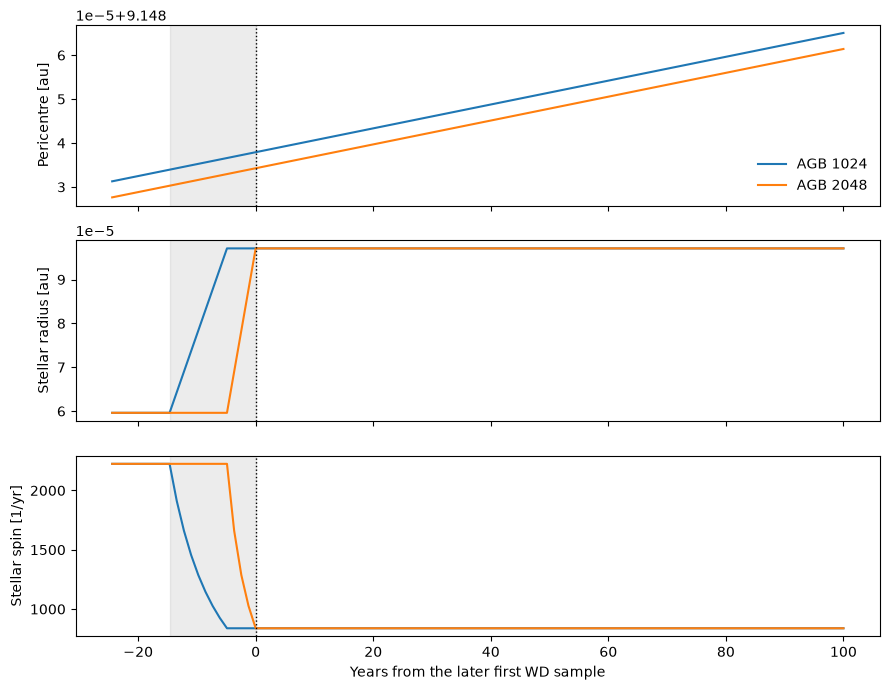

The 1024 track (blue) contracts and spins up earlier than the 2048 track (orange). Within the grey transition band the stellar phases can differ at the same age.  The shared 100-year comparison begins after both tracks reach the WD phase.

## 4. Explore the saved run

With the small reports present, the next cell prints the measured status and clearances. Enable `PLOT_SAVED_AGB` to plot the 2048 history or its compact preview. The dashed line gives the minimum across every saved sample.

In [ ]:
fine_report = REFERENCE / "validation_status.json"
checkpoint = REFERENCE / "finish_05_v1" / "notebook_05_checkpoint.json"

if fine_report.is_file():
    fine = read_json(fine_report)
    print("Pre-WD comparison:", fine["status"])
    for level in (1024, 2048):
        case = fine["summaries"][f"AGB{level}_n2"]
        print(f"  {level}: {case['outcome']}, minimum clearance {case['minimum_sampled_clearance_AU']:.9f} au")
else:
    print("Pre-WD report unavailable locally. The measured results are in section 3.")

if checkpoint.is_file():
    finish = read_json(checkpoint)
    print("Final status:", finish["status"])
    print("Entire WD transition:", finish["entire_WD_transition"])
    for check, passed in finish["checks"].items():
        print(f"  {check}: {passed}")
else:
    print("Final checkpoint unavailable locally:", checkpoint)


In [ ]:
if PLOT_SAVED_AGB:
    import matplotlib.pyplot as plt
    import numpy as np

    case_dir = REFERENCE / "combined_AGB2048_n2"
    history_path = case_dir / "history.npy"
    preview_path = case_dir / "clearance_preview.npz"
    if history_path.is_file():
        record = read_json(case_dir / "run.json")
        if record["status"] != "completed":
            raise ValueError("Choose a completed 2048 run before plotting its history.")
        table = np.load(history_path, mmap_mode="r", allow_pickle=False)
        count = record["n_states"]  # Only the written prefix of a disk-backed history is valid.
        if not 1 <= count <= len(table):
            raise ValueError("The recorded sample count does not match the saved history.")
        selection = np.linspace(0, count - 1, min(count, 3500), dtype=int)
        sample = table[selection]
        time_yr, clearance_AU = sample["time_yr"], sample["clearance_AU"]
        minimum = read_json(case_dir / "summary.json")["minimum_sampled_clearance_AU"]
    elif preview_path.is_file():
        with np.load(preview_path, allow_pickle=False) as preview:
            time_yr = preview["time_yr"]
            clearance_AU = preview["clearance_AU"]
            minimum = preview["minimum_sampled_clearance_AU"].item()
    else:
        raise FileNotFoundError(f"To plot the saved 2048 case, copy {preview_path} "
                                "or run.json, summary.json and history.npy from the same case.")

    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(time_yr / 1e6, clearance_AU, lw=1, label="Sampled orbit")
    ax.axhline(minimum, color="tab:orange", ls="--", label=f"Minimum over full history ({minimum:.4f} au)")
    ax.axhline(0, color="0.4", lw=0.8, label="Surface contact")
    ax.set(xlabel="Time since AGB entry [Myr]", ylabel="Planet–star clearance [au]")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


## Open questions

- In the frozen giant, how do the final orbit and closest approach change when `GIANT_STAR_VISCOUS_YR` drops from 1 to 0.1?
- How far apart are the last giant and first WD samples on each stellar track? Can finer stellar sampling resolve the phase and spin differences?
- What happens if the planet is already present before the giant phases? Notebook 06 starts the planet at 1 au at stellar age zero.
- What can we do to speed up some of the code? Can we use GPUs?